In [196]:
import sys
sys.path.append('../../src')

In [197]:
import pandas as pd
import numpy
from energiapy.components.temporal_scale import TemporalScale
from energiapy.components.resource import Resource, VaryingResource, Scope
from energiapy.components.process import Process, VaryingProcess
from energiapy.components.material import Material
from energiapy.components.location import Location
from energiapy.components.network import Network
from energiapy.components.scenario import Scenario
from energiapy.components.transport import Transport
from energiapy.model.formulate import formulate, Constraints, Objective
from energiapy.utils.nsrdb_utils import fetch_nsrdb_data
from energiapy.plot import plot_results, plot_scenario
from energiapy.plot.plot_results import CostY, CostX
from energiapy.model.solve import solve
from itertools import product
from energiapy.components.result import Result
from itertools import product
from matplotlib import rc
import matplotlib.pyplot as plt
from energiapy.model.solve import solve
from energiapy.plot.plot_results import CostY, CostX
from energiapy.components.location import Location
from energiapy.plot import plot_results, plot_scenario
from energiapy.utils.nsrdb_utils import fetch_nsrdb_data
from energiapy.model.formulate import formulate, Constraints, Objective
from energiapy.model.bounds import CapacityBounds
from energiapy.utils.data_utils import get_data, make_henry_price_df, remove_outliers, load_results
from energiapy.conversion.photovoltaic import solar_power_output
from energiapy.conversion.windmill import wind_power_output
from energiapy.model.constraints.integer_cuts import constraint_block_integer_cut, constraint_block_integer_cut_min
from scipy import stats

In [198]:
# To solve the scheduling level problem for the motivating example of 3 forms of LNG production with varying GWP (resets every year), varying ERCOT power prices & NG prices (fluctuates every hour for the next 5 years)
# For optimal cost vs emission scenario (and varying weights for emission reduction , eg, for 10% reduction in emission, what is the best case scenario)

In [199]:
horizon = 1
scales = TemporalScale(discretization_list=[5,4,91])

#1,24

In [200]:
bigM = 10**8
smallM = 0.001

In [201]:
import pandas as pd

# Read the Excel file into a DataFrame
elec_price_df = pd.read_csv('C:/Users/marcopdsousa/Documents/energiapy/AICHE/AICHE 2025 Data/Complete_ERCOT_Prices - 5 year_Daily.csv')
#elec_price_df = elec_price_df[:365].reset_index(drop = True)
elec_price_df = elec_price_df[:1820].reset_index(drop = True)
elec_price_df

# Increment index by 1 (optional, depending on what you want to do)
# elec_price_df.index = elec_price_df.index + 1

# Display DataFrame
# print(elec_price_df)

# Get the maximum price from the first column


,Settlement Point Price
0,14.70
1,18.45
2,17.73
3,13.60
4,16.14
...,...
1815,16.41
1816,19.66
1817,21.96
1818,14.41


In [202]:
#import pandas as pd

# # Read the Excel file into a DataFrame
# LNG_demand_df = pd.read_csv('C:/Users/marcopdsousa/Documents/energiapy/AICHE/AICHE 2025 Data/CorpusChristi_LNG.csv')
# LNG_demand_df = LNG_demand_df[['LNG Final']]
# LNG_demand_df = LNG_demand_df[:1825].reset_index(drop = True)
# #LNG_demand_df


import pandas as pd

# Read the Excel file into a DataFrame
LNG_demand_df = pd.read_csv('C:/Users/marcopdsousa/Documents/energiapy/AICHE/AICHE 2025 Data/CorpusChristi_LNG.csv')
LNG_demand_df = LNG_demand_df[['LNG FQ']]
LNG_demand_df = LNG_demand_df[:20].reset_index(drop = True)
LNG_demand_df 
#LNG_demand_df



,LNG FQ
0,1782564.524
1,1875872.854
2,1463448.206
3,1402097.293
4,1859535.239
5,1957717.097
6,1557430.210
7,1475460.199
8,1960934.388
9,2061632.989


In [203]:
# elec_price_df = pd.read_excel(r'C:\Users\marcopdsousa\Documents\energiapy\AICHE\AICHE 2025 Data\Complete_ERCOT_Prices_RepresentativeDay.xlsx')
# elec_price_df.index


In [204]:
# elec_price_df = pd.read_csv('C:/Users/marcopdsousa/Documents/energiapy/ESCAPE/Belgium Data/2024 Hourly Prices Belgium.csv')
# #elec_price_df = elec_price_df[elec_price_df['SettlementPoint'] == 'HB_HOUSTON']
# elec_price_df = elec_price_df[['Price (EUR/MWhe)']].reset_index(drop = True)
# elec_price_df = elec_price_df[:8760]
# elec_price_df['Price (EUR/MWhe)'] = elec_price_df['Price (EUR/MWhe)'].clip(lower=0)
# elec_price_df

In [205]:
# elec_price_df

In [206]:
# Formula verified

#for index in elec_price_df.index:
    #if index <= 20:
        #GWP_value = 112.23
    #elif index <= 70:
        #GWP_value = 99.99
    #elif index <= 72:
        #GWP_value = 92.84
    #else:
        #GWP_value = 83.82
    
    #print(f"Index: {index}, GWP_value: {GWP_value}")  # To check the values dynamically


In [207]:
# for index in elec_price_df.index:
#     if index <= 365:
#         GWP_value = 112.23
#     elif index >365 and index<= 730:
#         GWP_value = ((99.99*(index - 365))+(112.23*365))/(index)
#     elif index >730 and index<= 1095:
#         GWP_value = ((92.84*(index - 730))+(99.99*365)+(112.23*365))/index
#     elif index >1095 and index<= 1460:
#         GWP_value = ((87.76*(index - 1095))+(99.99*365)+(112.23*365)+(92.84*730))/index
#     else:
#         GWP_value= (83.82*((index - 1460))+(87.76*365)+(99.99*365)+(112.23*365)+(92.84*730))/index
#         # for 5 years

## True Fuel mix GWP

In [208]:
# # Fuel Mix GWP
# GWP_df = pd.read_excel(r'C:\Users\marcopdsousa\Documents\energiapy\AICHE\AICHE 2025 Data\GWP_FuelMix_Day1.xlsx')
# GWP_df.head()
# GWP_df.index

In [209]:
# #The natural gas price is calculated as the average between the high and low cost, also the unit used is $/kg of natural gas
# TVEF_df = pd.read_csv(r"C:/Users/marcopdsousa/Documents/energiapy/AICHE/AICHE 2025 Data/GWP_FuelMix.csv")
# # NG_price_df = pd.DataFrame(NG_price_df['USD/kg'])[::-1].reset_index()
# TVEF_df = TVEF_df[['GWP']]
# TVEF_df = TVEF_df[:1825].reset_index(drop = True)
# TVEF_df

In [210]:
# #The natural gas price is calculated as the average between the high and low cost, also the unit used is $/kg of natural gas
# GWP_df = pd.read_csv(r"C:/Users/marcopdsousa/Documents/energiapy/AICHE/AICHE 2025 Data/GWP_FuelMix.csv")
# # NG_price_df = pd.DataFrame(NG_price_df['USD/kg'])[::-1].reset_index()
# GWP_df = GWP_df[['Methane']]
# GWP_df = GWP_df[:1825].reset_index(drop = True)
# GWP_df

## Test GWP Mix


In [211]:
# #The natural gas price is calculated as the average between the high and low cost, also the unit used is $/kg of natural gas
# GWP_df = pd.read_csv('C:/Users/marcopdsousa/Documents/energiapy/ESCAPE/Belgium Data/2024 Carbon Intensity Belgium.csv')
# # NG_price_df = pd.DataFrame(NG_price_df['USD/kg'])[::-1].reset_index()
# GWP_df = GWP_df[['Carbon intensity Full']]
# GWP_df = GWP_df[:8760].reset_index(drop = True)
# GWP_df

In [212]:
# TVEF_value = TVEF_df.max()[0]
# GWP_value = GWP_df.max()[0]
elec_price = elec_price_df.max()[0]

C:\Users\marcopdsousa\AppData\Local\Temp\ipykernel_35940\4108844347.py:3: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  elec_price = elec_price_df.max()[0]


In [213]:
# Outputs

CO2 = Resource(name='CO2 Vented from the process', basis='kg/hr',
               label='Carbon dioxide vented from the process', block='Resource', gwp = 1, sell=True, scope = Scope.ONE)

Methane = Resource(name='Methane leaked from the process', basis='kg/hr',
               label='Methane from the process', block='Resource', cons_max = bigM, gwp = 27.9, sell=True, scope = Scope.ONE)

#gwp = 112.23
#cons_max = bigM, gwp = GWP_value, varying = [VaryingResource.DETERMINISTIC_GWP],

#MethaneD = Resource(name='Dynamic Methane emission', basis='kg', label='Methane emitted')

NGL = Resource(name='Natural Gas Liquids_in_extraction', basis='kg/hr', label='Natural Gas Liquids_in_extraction', block='Resource', sell=True)

ProducedWater = Resource(name='H2O vented from the process',
               basis='kg/hr', sell=True, label='Water vented from the process', block='Resource')

LNG = Resource(name='LNG', demand = True, basis='kg/hr', label='LNG', block='Resource', varying=[VaryingResource.DETERMINISTIC_DEMAND])

Boil_off_LNG = Resource(name='Boil_off_LNG', sell=True, basis='kg/hr', label='Boil_off_LNG', block='Resource')

Heat_Energy = Resource(name='Heat_Energy', basis='MW', label='Heat_Energy', sell=True, block='Resource')

#Methane = Resource(name='Methane leaked from the process', basis='kg/hr',
               #label='Methane from the process', block='Resource', gwp = GWP_value, varying = [VaryingResource.DETERMINISTIC_GWP], sell=True, scope = Scope.ONE)

# Inputs

Power = Resource(name='Power', basis='MW', label='Power generated')

GridPower = Resource(name='GridPower', basis='MW',
                     cons_max=bigM, label='Power bought', gwp= 313.92, price =elec_price ,varying = [VaryingResource.DETERMINISTIC_PRICE], scope = Scope.TWO)
# Grid Power GWP from average value of time-varying GWP

ResourceWater = Resource(name='H2O',
               basis='kg/hr', cons_max=bigM, label='Water', price = 0.002, block='Resource')

Proppant_Additive = Resource(name='Proppant_Additive', basis='kg/hr', label='Proppant_Additive', block='Resource', price= 0.975, cons_max=bigM)
# Reference Link: https://www.maximizemarketresearch.com/market-report/global-proppant-market/14899/?utm_source=chatgpt.com

Diesel = Resource(name='Diesel', basis='kg/hr', label='Diesel', block='Resource', price= 0.98, cons_max=bigM)
# Reference Link: https://businessanalytiq.com/procurementanalytics/index/diesel-price-index/

Cooling_Water_In_Liquifaction = Resource(name='Cooling_Water_In_Liquifaction', basis='kg/hr', label='Cooling_Water_In_Liquifaction', block='Resource', cons_max=bigM, price= 0.0572)
# Reference link: https://www.intratec.us/products/industry-economics-worldwide/utility/cooling-water-united-states

LNG =  Resource(name='LNG', demand=True, basis='kg/hr', label='LNG', block='Resource')

Glycol = Resource(name='Glycol', basis='kg/hr', label='Glycol', block='Resource', cons_max=bigM, price= 0.052)
# Reference link: https://businessanalytiq.com/procurementanalytics/index/ethylene-glycol-price-index/

MDEA = Resource(name='MDEA', basis='kg/hr', label='MDEA', block='Resource', cons_max=bigM)


DP1 = Resource(name='DP1', basis='kg/hr', cons_max= 988, price=4, 
               label='DP1', block='Resource') #5% deviation
DP2 = Resource(name='DP2', basis='kg/hr', cons_max= 988, price=9, 
               label='DP2', block='Resource') #10% deviation 1976
DP3 = Resource(name='DP3', basis='kg/hr', cons_max= 988, price= 15, 
               label='DP3', block='Resource') #15% deviation 2965
DP4 = Resource(name='DP4', basis='kg/hr', cons_max= 988, price= 21, 
               label='DP4', block='Resource') #20% deviation 3953
DP5 = Resource(name='DP5', basis='kg/hr', cons_max= 988, price= 29, 
               label='DP5', block='Resource') #25% deviation 4942
DP6 = Resource(name='DP6', basis='kg/hr', cons_max= 988, price= 37, 
               label='DP6', block='Resource') #30% deviation 5930
#========================================================================================================
# DP1 = Resource(name='DP1', basis='kg/hr', cons_max= 750, price=10, 
#                label='DP1', block='Resource') #5% deviation
# DP2 = Resource(name='DP2', basis='kg/hr', cons_max= 2250, price=25, 
#                label='DP2', block='Resource') #15% deviation
# DP3 = Resource(name='DP3', basis='kg/hr', cons_max= 4000, price= 50, 
#                label='DP3', block='Resource') #27% deviation
# DP4 = Resource(name='DP4', basis='kg/hr', cons_max= 5250, price= 115, 
#                label='DP4', block='Resource')

In [214]:
print(elec_price_df.shape[0])

1820


In [215]:
# FU: 1 kg/hr of LNG
# 3 methane producing processes

Grid = Process(name='Grid', conversion={GridPower: -1, Power: 1}, prod_min=smallM, prod_max=bigM, label='Grid', basis='MW')

#MDGWP = Process(name='MDGWP', conversion={Methane: -1, MethaneD: 1}, prod_min=smallM, prod_max=bigM, label='MDGWP', basis='kg')

Conventional_NG = Process(name='Conventional_NG', conversion={Boil_off_LNG: 0.01, Power: -0.0028, ResourceWater: -0.5, Diesel: -0.000741382, Glycol: -0.000818111, MDEA: -0.012391658, Cooling_Water_In_Liquifaction: -1.75,
                                                              Methane: 0.00395, CO2: 0.966504505 , NGL: 0.3, Heat_Energy: 0.02, ProducedWater: 0.912, LNG: 1}, capex=0.17, fopex=1.5, vopex=1.5, prod_min=0.1, prod_max=bigM, label='Conventional LNG', basis='kg/hr')  

ShaleGas = Process(name='ShaleGas', conversion={Boil_off_LNG: 0.01, Power: -0.003, ResourceWater: -0.92, Diesel: -0.002041766, Glycol: -0.01875, MDEA: -0.284, Cooling_Water_In_Liquifaction: -2.75,
                                                              Methane: 0.00895, CO2: 2.1, NGL: 1.9, Heat_Energy: 0.074, ProducedWater: 2.2205, LNG: 1}, capex=0.19, fopex=0.6, vopex=0.6, prod_min=0.1, prod_max=bigM, label='ShaleGas', basis='kg/hr')

Coalbed = Process(name='Coalbed', conversion={Boil_off_LNG: 0.01, Power: -0.01, Diesel: -0.075, Glycol: -0.026539527, MDEA: -0.401985372, Cooling_Water_In_Liquifaction: -3.25,
                                                              Methane: 0.811, CO2: 5.823126126, NGL: 0.062761905, Heat_Energy: 0.002, ProducedWater: 6.2755, LNG: 1}, capex=0.205, fopex=2.24, vopex=1.17, prod_min=0.1, prod_max=bigM, label='CoalBed', basis='kg/hr')


D1 = Process(name="D1", conversion={DP1:-1, LNG:1}, capex=0, vopex=0, fopex=0, prod_min=0, prod_max=bigM, label='D1', basis='kg/hr')
D2 = Process(name="D2", conversion={DP2:-1, LNG:1}, capex=0, vopex=0, fopex=0, prod_min=0, prod_max=bigM, label='D2', basis='kg/hr')
D3 = Process(name="D3", conversion={DP3:-1, LNG:1}, capex=0, vopex=0, fopex=0, prod_min=0, prod_max=bigM, label='D3', basis='kg/hr')
D4 = Process(name="D4", conversion={DP4:-1, LNG:1}, capex=0, vopex=0, fopex=0, prod_min=0, prod_max=bigM, label='D4', basis='kg/hr')
D5 = Process(name="D5", conversion={DP5:-1, LNG:1}, capex=0, vopex=0, fopex=0, prod_min=0, prod_max=bigM, label='D5', basis='kg/hr')
D6 = Process(name="D6", conversion={DP6:-1, LNG:1}, capex=0, vopex=0, fopex=0, prod_min=0, prod_max=bigM, label='D6', basis='kg/hr')
#================================================================================================



# D1 = Process(name="D1", conversion={DP1:-1, H2Pure:1}, capex=0, vopex=0, fopex=0, prod_min=0, prod_max=bigM, label='D1', basis='kg/hr')
# D2 = Process(name="D2", conversion={DP2:-1, H2Pure:1}, capex=0, vopex=0, fopex=0, prod_min=0, prod_max=bigM, label='D2', basis='kg/hr')
# D3 = Process(name="D3", conversion={DP3:-1, H2Pure:1}, capex=0, vopex=0, fopex=0, prod_min=0, prod_max=bigM, label='D3', basis='kg/hr')
# D4 = Process(name="D4", conversion={DP4:-1, H2Pure:1}, capex=0, vopex=0, fopex=0, prod_min=0, prod_max=bigM, label='D4', basis='kg/hr')

# capacity needed? No

# https://marcelluscoalition.org/wp-content/uploads/2012/07/The-Arithmetic-of-Shale-Gas.pdf

# https://shareholdersunite.com/the-ioc-files-useful-background-material/the-economics-of-lng/

In [216]:
process_set = {Grid, Conventional_NG, ShaleGas, Coalbed, D1,D2,D3,D4,D5,D6}

#, D1,D2,D3,D4,D5,D6

In [217]:
# network scale level is 2, due to indexing issues. However, this shouldn't change the final output as capex is smallM. Fopex will be mentiond in hourly level
#{Methane:GWP_value, GridPower: GWP_df}

houston = Location(name='Houston', processes=process_set,  price_factor={GridPower: elec_price_df},demand_factor={LNG: LNG_demand_df}, expenditure_scale_level=0,
                   scales=scales, label='Houston', demand_scale_level=1, price_scale_level=2, gwp_scale_level = 2)


In [218]:

scenario = Scenario(name='scenario_full', network=houston, scales=scales,  demand_scale_level=1, expenditure_scale_level=0,
                    purchase_scale_level = 2, scheduling_scale_level=2, network_scale_level=0, gwp_scale_level = 2, 
                    label='full_case', demand={houston: {LNG:2265757}})

In [219]:
print("Contents of scenario.gwp_dict:", Location.gwp_factor)
#code not reading demand or gwp factor

Contents of scenario.gwp_dict: None


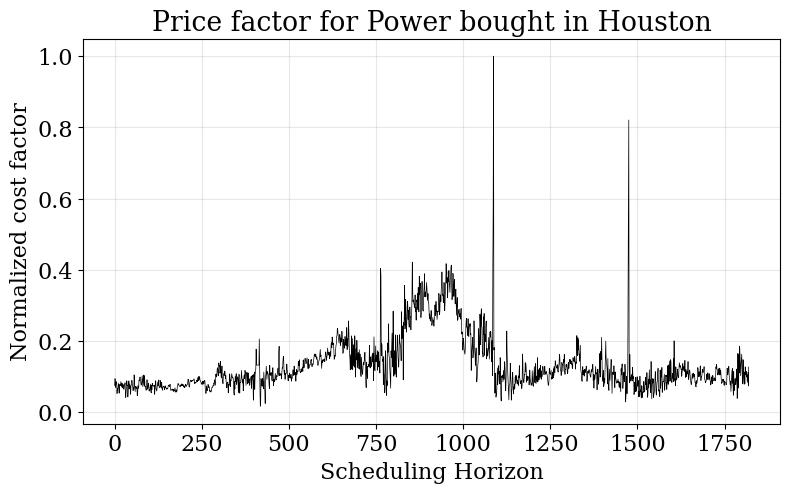

In [220]:
plot_scenario.price_factor(scenario=scenario, location=houston, resource=GridPower, fig_size=(9, 5), color='black')

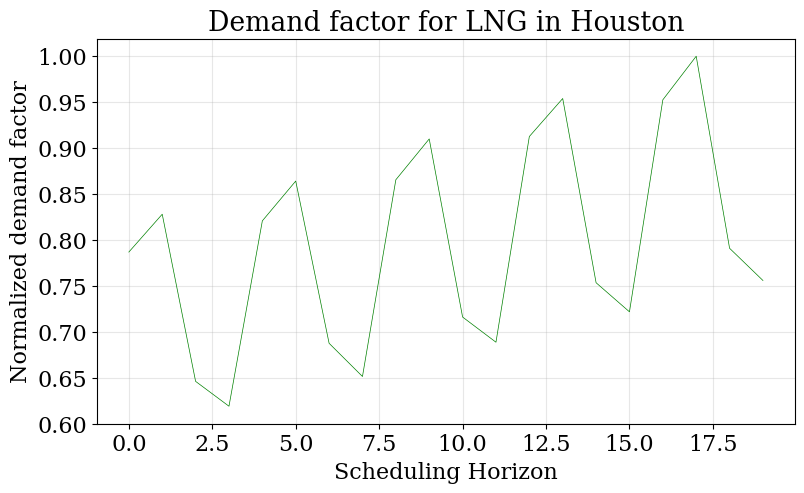

In [221]:
plot_scenario.demand_factor(
     scenario=scenario, location=houston, resource=LNG, fig_size=(9, 5), color='green')

In [222]:
# plot_scenario.demand_factor(
#     scenario=scenario, location=houston, resource=LNG, fig_size=(9, 5), color='green')

In [223]:
#, Constraints.MODE

milp_cost = formulate(scenario=scenario, constraints={Constraints.COST, Constraints.INVENTORY, Constraints.PRODUCTION, Constraints.NETWORK,
                      Constraints.RESOURCE_BALANCE, Constraints.DEMAND, Constraints.EMISSION}, objective=Objective.COST, demand_sign = 'eq')

constraint process capex
constraint process fopex
constraint process vopex
constraint storage capex
constraint process incidental
constraint location capex
constraint storage cost
constraint storage cost location
constraint storage cost network
constraint global warming potential resource
constraint global warming potential resource consumption
constraint global warming potential resource discharge
constraint global warming potential location
constraint global warming potential network
constraint production mode
constraint inventory balance
constraint inventory network
constraint storage facility
constraint production facility
constraint min production facility
constraint min storage facility
constraint demand
objective cost


## Capacity constrained ramping based on Nameplate Capacity

In [224]:
from pyomo.environ import ConstraintList

# Loop of how this code runs
# Constraint 1: except for the first value (year 1, day 1, hour 0), all the other values ramp up as per the previous production rate   *scales.scale_iter(1)[scales.scale_iter(1).index(i) - 1]
# *scales.scale_iter(1)[scales.scale_iter(1).index(i) - 1]

milp_cost.cons1 = ConstraintList()
for i in scales.scale_iter(2):
    if i != (0,0,0):
        milp_cost.cons1.add(expr = milp_cost.P['Houston', 'Conventional_NG', *i] - milp_cost.P['Houston', 'Conventional_NG', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] <= 0.10* milp_cost.Cap_P['Houston', 'Conventional_NG',  i[0]])

#Constraint 2: Ramp down

milp_cost.cons2 = ConstraintList()
for i in scales.scale_iter(2):
    if i != (0,0,0):
        milp_cost.cons2.add(expr = milp_cost.P['Houston', 'Conventional_NG', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] - milp_cost.P['Houston', 'Conventional_NG', *i] <= 0.10*milp_cost.Cap_P['Houston', 'Conventional_NG',  i[0]])


# Loop of how this code runs
# Constraint 1: except for the first value (year 1, day 1, hour 0), all the other values ramp up as per the previous production rate
milp_cost.cons3 = ConstraintList()
for i in scales.scale_iter(2):
    if i != (0,0,0):
        milp_cost.cons3.add(expr = milp_cost.P['Houston', 'ShaleGas', *i] - milp_cost.P['Houston', 'ShaleGas', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] <= 0.2* milp_cost.Cap_P['Houston', 'ShaleGas', i[0]])

#Constraint 2: Ramp down

milp_cost.cons4 = ConstraintList()
for i in scales.scale_iter(2):
    if i != (0,0,0):
        milp_cost.cons4.add(expr = milp_cost.P['Houston', 'ShaleGas', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] - milp_cost.P['Houston', 'ShaleGas', *i] <= 0.2*milp_cost.Cap_P['Houston', 'ShaleGas', i[0]])

# Loop of how this code runs
# Constraint 1: except for the first value (year 1, day 1, hour 0), all the other values ramp up as per the previous production rate
milp_cost.cons5 = ConstraintList()
for i in scales.scale_iter(2):
    if i != (0,0,0):
        milp_cost.cons5.add(expr = milp_cost.P['Houston', 'Coalbed', *i] - milp_cost.P['Houston', 'Coalbed', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] <= 0.15* milp_cost.Cap_P['Houston', 'Coalbed', i[0]])

#Constraint 2: Ramp down

milp_cost.cons6 = ConstraintList()
for i in scales.scale_iter(2):
    if i != (0,0,0):
        milp_cost.cons6.add(expr = milp_cost.P['Houston', 'Coalbed', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] - milp_cost.P['Houston', 'Coalbed', *i] <= 0.15*milp_cost.Cap_P['Houston', 'Coalbed', i[0]])


milp_cost.cons7 = ConstraintList()
for i in scales.scale_iter(2):
    #if i != (0,0):
    milp_cost.cons7.add(expr = milp_cost.P['Houston', 'Conventional_NG', *i] >= 0.5*milp_cost.Cap_P['Houston','Conventional_NG', i[0]])

#0.35*milp_cost.Cap_P['Houston','Conventional_NG', i[0]])

milp_cost.cons8 = ConstraintList()
for i in scales.scale_iter(2):
    #if i != (0,0):
    milp_cost.cons8.add(expr = milp_cost.P['Houston', 'ShaleGas', *i] >= 0.35*milp_cost.Cap_P['Houston','ShaleGas', i[0]])

#0.35*milp_cost.Cap_P['Houston','ShaleGas', i[0]]

milp_cost.cons9 = ConstraintList()
for i in scales.scale_iter(2):
    #if i != (0,0):
    milp_cost.cons9.add(expr = milp_cost.P['Houston', 'Coalbed', *i] >= 0.35*milp_cost.Cap_P['Houston','Coalbed', i[0]])

# 0.35*milp_cost.Cap_P['Houston','Coalbed', i[0]]

## Ramping Constraints - Presently linked to production rate on previous timestep

In [225]:
# from pyomo.environ import ConstraintList

# # Constraint 1: except for the first value (year 1, day 1, hour 0), all the other values ramp up as per the previous production rate
# milp_cost.cons1 = ConstraintList()
# for i in scales.scale_iter(1):
#     if i != (0, 0):
#         milp_cost.cons1.add(expr=milp_cost.P['Houston', 'Conventional_NG', *i] - milp_cost.P['Houston', 'Conventional_NG', *scales.scale_iter(1)[scales.scale_iter(1).index(i) - 1]] <= 0.15 * milp_cost.P['Houston', 'Conventional_NG', *scales.scale_iter(1)[scales.scale_iter(1).index(i) - 1]])

# # Constraint 2: Ramp down
# milp_cost.cons2 = ConstraintList()
# for i in scales.scale_iter(1):
#     if i != (0, 0):
#         milp_cost.cons2.add(milp_cost.P['Houston', 'Conventional_NG', *scales.scale_iter(1)[scales.scale_iter(1).index(i) - 1]] - milp_cost.P['Houston', 'Conventional_NG', *i] <= 0.15 * milp_cost.P['Houston', 'Conventional_NG', *scales.scale_iter(1)[scales.scale_iter(1).index(i) - 1]])

# # Constraint 1: except for the first value (year 1, day 1, hour 0), all the other values ramp up as per the previous production rate
# milp_cost.cons3 = ConstraintList()
# for i in scales.scale_iter(1):
#     if i != (0, 0):
#         milp_cost.cons3.add(expr=milp_cost.P['Houston', 'ShaleGas', *i] - milp_cost.P['Houston', 'ShaleGas', *scales.scale_iter(1)[scales.scale_iter(1).index(i) - 1]] <= 0.15 * milp_cost.P['Houston', 'ShaleGas', *scales.scale_iter(1)[scales.scale_iter(1).index(i) - 1]])

# # Constraint 2: Ramp down
# milp_cost.cons4 = ConstraintList()
# for i in scales.scale_iter(1):
#     if i != (0, 0):
#         milp_cost.cons4.add(milp_cost.P['Houston', 'ShaleGas', *scales.scale_iter(1)[scales.scale_iter(1).index(i) - 1]] - milp_cost.P['Houston', 'ShaleGas', *i] <= 0.15 * milp_cost.P['Houston', 'ShaleGas', *scales.scale_iter(1)[scales.scale_iter(1).index(i) - 1]])

# # Constraint 1: except for the first value (year 1, day 1, hour 0), all the other values ramp up as per the previous production rate
# milp_cost.cons5 = ConstraintList()
# for i in scales.scale_iter(1):
#     if i != (0, 0):
#         milp_cost.cons5.add(expr=milp_cost.P['Houston', 'Coalbed', *i] - milp_cost.P['Houston', 'Coalbed', *scales.scale_iter(1)[scales.scale_iter(1).index(i) - 1]] <= 0.15 * milp_cost.P['Houston', 'Coalbed', *scales.scale_iter(1)[scales.scale_iter(1).index(i) - 1]])

# # Constraint 2: Ramp down
# milp_cost.cons6 = ConstraintList()
# for i in scales.scale_iter(1):
#     if i != (0, 0):
#         milp_cost.cons6.add(milp_cost.P['Houston', 'Coalbed', *scales.scale_iter(1)[scales.scale_iter(1).index(i) - 1]] - milp_cost.P['Houston', 'Coalbed', *i] <= 0.15 * milp_cost.P['Houston', 'Coalbed', *scales.scale_iter(1)[scales.scale_iter(1).index(i) - 1]])


In [226]:
results_cost = solve(scenario=scenario, instance=milp_cost,
                     solver='gurobi', name=f"res_cost", print_solversteps=True, saveformat = '.pkl')

Set parameter OutputFlag to value 1
Set parameter QCPDual to value 1
Gurobi Optimizer version 12.0.1 build v12.0.1rc0 (win64 - Windows 11.0 (26100.2))

CPU model: 13th Gen Intel(R) Core(TM) i7-13700, instruction set [SSE2|AVX|AVX2]
Thread count: 16 physical cores, 24 logical processors, using up to 24 threads

Non-default parameters:
QCPDual  1

Optimize a model with 208334 rows, 1067551 columns and 693032 nonzeros
Model fingerprint: 0x3aae96d2
Variable types: 1067501 continuous, 50 integer (50 binary)
Coefficient statistics:
  Matrix range     [7e-04, 1e+08]
  Objective range  [1e+00, 1e+00]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+03, 1e+08]
Presolve removed 170060 rows and 1047461 columns
Presolve time: 0.12s
Presolved: 38274 rows, 20090 columns, 107442 nonzeros
Variable types: 20040 continuous, 50 integer (20 binary)
Performing another presolve...
Presolve removed 16390 rows and 14481 columns
Presolve time: 1.34s

Root relaxation: objective 3.020089e+07, 3132 iterat

In [227]:
results_cost.output['objective']

30200894.23746552

In [228]:
#3073157.7669820026/3650000
22497350.818022832/36078038.04

30200894/36078038
# #3047005.0671211183
# 331132.03203138924
# 263313.3374685114

0.8370991238492514

In [229]:
results_cost.output['X_P']

{('Houston', 'Coalbed', 0): -0.0,
 ('Houston', 'Coalbed', 1): -0.0,
 ('Houston', 'Coalbed', 2): -0.0,
 ('Houston', 'Coalbed', 3): -0.0,
 ('Houston', 'Coalbed', 4): 0.0,
 ('Houston', 'Conventional_NG', 0): -0.0,
 ('Houston', 'Conventional_NG', 1): -0.0,
 ('Houston', 'Conventional_NG', 2): -0.0,
 ('Houston', 'Conventional_NG', 3): -0.0,
 ('Houston', 'Conventional_NG', 4): -0.0,
 ('Houston', 'D1', 0): 1.0,
 ('Houston', 'D1', 1): 1.0,
 ('Houston', 'D1', 2): 1.0,
 ('Houston', 'D1', 3): 1.0,
 ('Houston', 'D1', 4): 1.0,
 ('Houston', 'D2', 0): 1.0,
 ('Houston', 'D2', 1): 1.0,
 ('Houston', 'D2', 2): 1.0,
 ('Houston', 'D2', 3): 1.0,
 ('Houston', 'D2', 4): 1.0,
 ('Houston', 'D3', 0): 1.0,
 ('Houston', 'D3', 1): 1.0,
 ('Houston', 'D3', 2): 1.0,
 ('Houston', 'D3', 3): 1.0,
 ('Houston', 'D3', 4): 1.0,
 ('Houston', 'D4', 0): 1.0,
 ('Houston', 'D4', 1): 1.0,
 ('Houston', 'D4', 2): 1.0,
 ('Houston', 'D4', 3): 1.0,
 ('Houston', 'D4', 4): 1.0,
 ('Houston', 'D5', 0): 1.0,
 ('Houston', 'D5', 1): 1.0,
 ('Ho

In [230]:
results_cost.output['P']

{('Houston', 'Coalbed', 0, 0, 0): 0.0,
 ('Houston', 'Coalbed', 0, 0, 1): 0.0,
 ('Houston', 'Coalbed', 0, 0, 2): 0.0,
 ('Houston', 'Coalbed', 0, 0, 3): 0.0,
 ('Houston', 'Coalbed', 0, 0, 4): 0.0,
 ('Houston', 'Coalbed', 0, 0, 5): 0.0,
 ('Houston', 'Coalbed', 0, 0, 6): 0.0,
 ('Houston', 'Coalbed', 0, 0, 7): 0.0,
 ('Houston', 'Coalbed', 0, 0, 8): 0.0,
 ('Houston', 'Coalbed', 0, 0, 9): 0.0,
 ('Houston', 'Coalbed', 0, 0, 10): 0.0,
 ('Houston', 'Coalbed', 0, 0, 11): 0.0,
 ('Houston', 'Coalbed', 0, 0, 12): 0.0,
 ('Houston', 'Coalbed', 0, 0, 13): 0.0,
 ('Houston', 'Coalbed', 0, 0, 14): 0.0,
 ('Houston', 'Coalbed', 0, 0, 15): 0.0,
 ('Houston', 'Coalbed', 0, 0, 16): 0.0,
 ('Houston', 'Coalbed', 0, 0, 17): 0.0,
 ('Houston', 'Coalbed', 0, 0, 18): 0.0,
 ('Houston', 'Coalbed', 0, 0, 19): 0.0,
 ('Houston', 'Coalbed', 0, 0, 20): 0.0,
 ('Houston', 'Coalbed', 0, 0, 21): 0.0,
 ('Houston', 'Coalbed', 0, 0, 22): 0.0,
 ('Houston', 'Coalbed', 0, 0, 23): 0.0,
 ('Houston', 'Coalbed', 0, 0, 24): 0.0,
 ('Houston

In [231]:
results_cost.output['global_warming_potential_location']

{('Houston', 0): 118749609.75309132,
 ('Houston', 1): 118749609.75309132,
 ('Houston', 2): 118749609.75309132,
 ('Houston', 3): 118749609.75309132,
 ('Houston', 4): 118749609.75309132}

In [ ]:
data = results_cost.output['global_warming_potential_resource']
df = pd.DataFrame(data,index=[0])
df = df.T
# Export the DataFrame to an Excel file
df.to_excel('C:\\Users\\marcopdsousa\\Desktop\\AICHE 2025\\AICHE GWP EF Emission Breakdown.xlsx', index=True)

In [245]:
118749609.75309132*4/36078038

13.165861153878858

In [233]:
# 104018031.60915612-101347319.03178307

127396965.39189774-124510725.55498487

2886239.8369128704

In [234]:
results_cost.output['Cap_P']

{('Houston', 'Coalbed', 0): 0.0,
 ('Houston', 'Coalbed', 1): 0.0,
 ('Houston', 'Coalbed', 2): 0.0,
 ('Houston', 'Coalbed', 3): 0.0,
 ('Houston', 'Coalbed', 4): 0.0,
 ('Houston', 'Conventional_NG', 0): 0.0,
 ('Houston', 'Conventional_NG', 1): 0.0,
 ('Houston', 'Conventional_NG', 2): 0.0,
 ('Houston', 'Conventional_NG', 3): 0.0,
 ('Houston', 'Conventional_NG', 4): 0.0,
 ('Houston', 'D1', 0): 100000000.0,
 ('Houston', 'D1', 1): 100000000.0,
 ('Houston', 'D1', 2): 100000000.0,
 ('Houston', 'D1', 3): 100000000.0,
 ('Houston', 'D1', 4): 100000000.0,
 ('Houston', 'D2', 0): 100000000.0,
 ('Houston', 'D2', 1): 100000000.0,
 ('Houston', 'D2', 2): 100000000.0,
 ('Houston', 'D2', 3): 100000000.0,
 ('Houston', 'D2', 4): 100000000.0,
 ('Houston', 'D3', 0): 100000000.0,
 ('Houston', 'D3', 1): 100000000.0,
 ('Houston', 'D3', 2): 100000000.0,
 ('Houston', 'D3', 3): 100000000.0,
 ('Houston', 'D3', 4): 100000000.0,
 ('Houston', 'D4', 0): 100000000.0,
 ('Houston', 'D4', 1): 100000000.0,
 ('Houston', 'D4',

[13584.752454478039, 8644.84247103148, 8644.84247103148, 13584.752454478039, 9879.81996689312, 14819.729950339679, 19759.63993378624, 24699.549917232798, 24699.549917232798, 24699.549917232798, 24699.549917232798, 19759.63993378624, 24699.549917232798, 24699.549917232798, 24699.549917232798, 24699.549917232798, 24699.549917232798, 19759.63993378624, 14819.729950339679, 19759.63993378624, 24699.549917232798, 19759.63993378624, 19759.63993378624, 24699.549917232798, 24699.549917232798, 24699.549917232798, 24699.549917232798, 24699.549917232798, 24699.549917232798, 24699.549917232798, 19759.63993378624, 24699.549917232798, 24699.549917232798, 24699.549917232798, 24699.549917232798, 19759.63993378624, 24699.549917232798, 24699.549917232798, 24699.549917232798, 24699.549917232798, 24699.549917232798, 19759.63993378624, 24699.549917232798, 19759.63993378624, 24699.549917232798, 24699.549917232798, 24699.549917232798, 24451.941309597292, 19512.031326150733, 14572.121342704173, 9879.8199668931

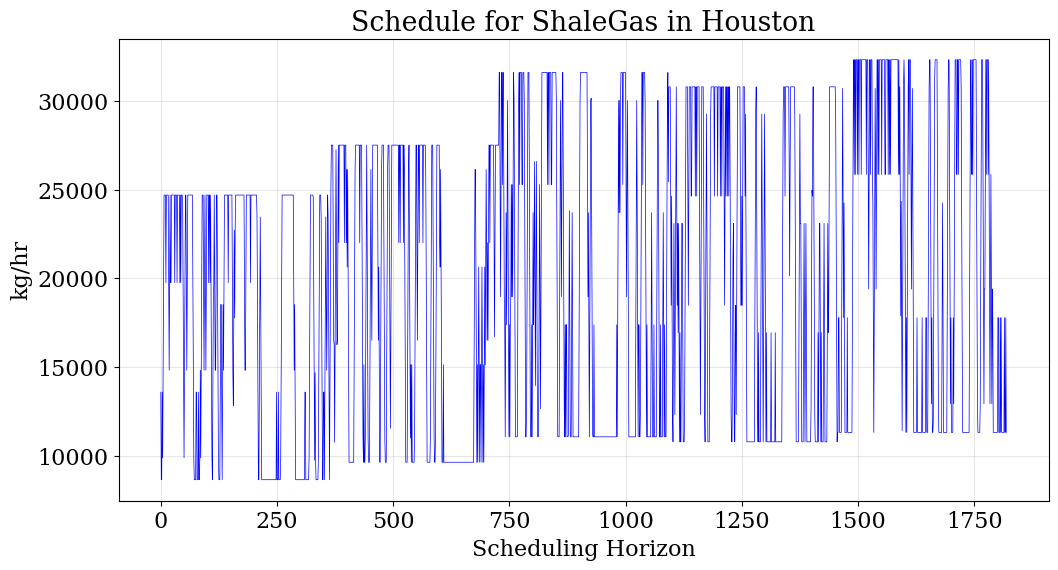

In [235]:
plot_results.schedule(results = results_cost, y_axis= 'P', component = 'ShaleGas', location='Houston')

[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,

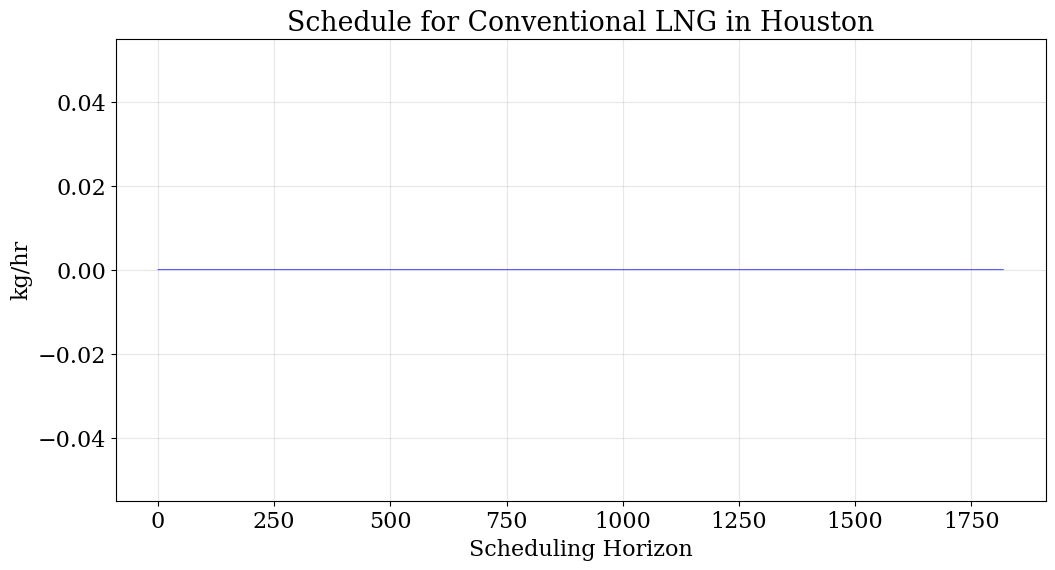

In [236]:
plot_results.schedule(results = results_cost, y_axis= 'P', component = 'Conventional_NG', location='Houston')

In [237]:
data1 = results_cost.output['P']
df1 = pd.DataFrame(data1,index=[0])
df1 = df1.T
# Export the DataFrame to an Excel file
df1.to_excel('C:\\Users\\marcopdsousa\\Desktop\\AICHE 2025\\SanityCheckQuarterDemandMinCost.xlsx', index=True)

In [238]:
from energiapy.model.constraints.emission import constraint_global_warming_potential_network_reduction
from pyomo.environ import Var, Binary

def modeler(gwp_pct: float):
    gwp_eval = formulate(scenario=scenario, constraints={Constraints.COST, Constraints.INVENTORY, Constraints.PRODUCTION, Constraints.NETWORK,
                        Constraints.RESOURCE_BALANCE, Constraints.DEMAND, Constraints.EMISSION}, objective=Objective.COST, demand_sign = 'geq')
    gwp_eval.cons2 = ConstraintList()
    gwp_eval.cons3 = ConstraintList()
    gwp_eval.cons4 = ConstraintList()
    gwp_eval.cons5 = ConstraintList()
    gwp_eval.cons8 = ConstraintList()
    gwp_eval.cons9 = ConstraintList()
    gwp_eval.cons10 = ConstraintList()
    gwp_eval.cons11 = ConstraintList()
    gwp_eval.cons13 = ConstraintList()
    gwp_eval.cons14 = ConstraintList()
    gwp_eval.cons15 = ConstraintList()
    gwp_eval.cons17 = ConstraintList()

    for i in scales.scale_iter(2):
        gwp_eval.cons10.add(expr = gwp_eval.P['Houston', 'Conventional_NG', *i] >= 0.5*gwp_eval.Cap_P['Houston','Conventional_NG', i[0]]) #30% of max production rate 6000 * milp_cost.on_smr[i]
        gwp_eval.cons11.add(expr = gwp_eval.P['Houston', 'ShaleGas', *i] >= 0.35*gwp_eval.Cap_P['Houston','ShaleGas', i[0]]) #20% of max production rate
        gwp_eval.cons13.add(expr = gwp_eval.P['Houston', 'Coalbed', *i] >= 0.35*gwp_eval.Cap_P['Houston','Coalbed', i[0]]) #20% of max production rate
        # gwp_eval.cons14.add(expr = gwp_eval.P['Houston', 'Conventional_NG', *i] <=gwp_eval.Cap_P['Houston','Conventional_NG', i[0]])
        # gwp_eval.cons15.add(expr = gwp_eval.P['Houston', 'ShaleGas', *i] <= gwp_eval.Cap_P['Houston','ShaleGas', i[0]])
        # gwp_eval.cons17.add(expr = gwp_eval.P['Houston', 'Coalbed', *i] <= gwp_eval.Cap_P['Houston','Coalbed', i[0]])
    if i != (0,0,0):
            gwp_eval.cons2.add(expr = gwp_eval.P['Houston', 'Conventional_NG', *i] - gwp_eval.P['Houston', 'Conventional_NG', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] <= 0.10* gwp_eval.Cap_P['Houston', 'Conventional_NG', i[0]])
            gwp_eval.cons3.add(expr = gwp_eval.P['Houston', 'Conventional_NG', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] - gwp_eval.P['Houston', 'Conventional_NG', *i] <= 0.10*gwp_eval.Cap_P['Houston', 'Conventional_NG', i[0]])
            gwp_eval.cons4.add(expr = gwp_eval.P['Houston', 'ShaleGas', *i] - gwp_eval.P['Houston', 'ShaleGas', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] <= 0.2* gwp_eval.Cap_P['Houston', 'ShaleGas', i[0]])
            gwp_eval.cons5.add(expr = gwp_eval.P['Houston', 'ShaleGas', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] - gwp_eval.P['Houston', 'ShaleGas', *i] <= 0.2*gwp_eval.Cap_P['Houston', 'ShaleGas', i[0]])
            gwp_eval.cons8.add(expr = gwp_eval.P['Houston', 'Coalbed', *i] - gwp_eval.P['Houston', 'Coalbed', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] <= 0.15* gwp_eval.Cap_P['Houston', 'Coalbed', i[0]])
            gwp_eval.cons9.add(expr = gwp_eval.P['Houston', 'Coalbed', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] - gwp_eval.P['Houston', 'Coalbed', *i] <= 0.15*gwp_eval.Cap_P['Houston', 'Coalbed', i[0]])
 
    constraint_global_warming_potential_network_reduction(instance= gwp_eval, network_scale_level = 0, gwp_reduction_pct = gwp_pct, gwp = results_cost.output['global_warming_potential_network'][0])
    
    return gwp_eval

In [239]:
models = [modeler((i+1)*5) for i in range(20)]

constraint process capex
constraint process fopex
constraint process vopex
constraint storage capex
constraint process incidental
constraint location capex
constraint storage cost
constraint storage cost location
constraint storage cost network
constraint global warming potential resource
constraint global warming potential resource consumption
constraint global warming potential resource discharge
constraint global warming potential location
constraint global warming potential network
constraint production mode
constraint inventory balance
constraint inventory network
constraint storage facility
constraint production facility
constraint min production facility
constraint min storage facility
constraint demand
objective cost
constraint global warming potential network reduction
constraint process capex
constraint process fopex
constraint process vopex
constraint storage capex
constraint process incidental
constraint location capex
constraint storage cost
constraint storage cost locatio

In [240]:
import os

# Create the 'res_red' directory if it doesn't exist
os.makedirs('res_red', exist_ok=True)

def solver(instance, i): 
    return solve(
        scenario=scenario, 
        instance=instance,
        solver='gurobi', 
        name=f"res_red/res_red_{i}", 
        print_solversteps=True, 
        saveformat='.pkl'
    )

# Assuming 'models' is a list of instances to be solved
results = {i: solver(m, i) for i, m in enumerate(models)}

Set parameter OutputFlag to value 1
Set parameter QCPDual to value 1
Gurobi Optimizer version 12.0.1 build v12.0.1rc0 (win64 - Windows 11.0 (26100.2))

CPU model: 13th Gen Intel(R) Core(TM) i7-13700, instruction set [SSE2|AVX|AVX2]
Thread count: 16 physical cores, 24 logical processors, using up to 24 threads

Non-default parameters:
QCPDual  1

Optimize a model with 197431 rows, 1067551 columns and 660313 nonzeros
Model fingerprint: 0xf4650d67
Variable types: 1067501 continuous, 50 integer (50 binary)
Coefficient statistics:
  Matrix range     [7e-04, 1e+08]
  Objective range  [1e+00, 1e+00]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+03, 1e+08]
Presolve removed 162780 rows and 1040176 columns
Presolve time: 0.13s
Presolved: 34651 rows, 27375 columns, 129323 nonzeros
Variable types: 27325 continuous, 50 integer (20 binary)
Performing another presolve...
Presolve removed 23629 rows and 21921 columns
Presolve time: 0.12s

Root relaxation: objective 3.388903e+07, 4093 iterat

In [241]:
for i in range(len(models)):
    print(results[i].output['termination'])

optimal
optimal
optimal
optimal
optimal
optimal
optimal
optimal
optimal
optimal
optimal
infeasible
infeasible
infeasible
infeasible
infeasible
infeasible
infeasible
infeasible
infeasible


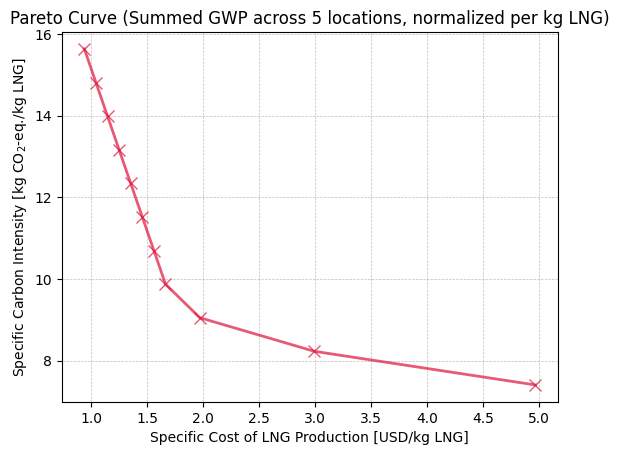

In [242]:
import numpy as np
import matplotlib.pyplot as plt

total_LNG_produced = 36078038  # total LNG produced in kg

cost = [None for _ in range(len(results))]
gwp_study = [None for _ in range(len(results))]
prod_study = [None for _ in range(len(results))]

for gwp_red, result in results.items():
    if result.output['termination'] == 'optimal':
        cost[gwp_red] = result.output['objective']

        # --- Sum over all 5 GWP location values ---
        total_gwp = 0
        for loc_index in range(5):  # assuming 5 time steps or location indices
            total_gwp += result.output['global_warming_potential_location']['Houston', loc_index]

        # --- Normalize total GWP by total LNG produced ---
        gwp_study[gwp_red] = total_gwp / total_LNG_produced

        # Keep production info (optional)
        prod_study[gwp_red] = result.output['P']

# --- Clean up None entries ---
mask = [c is not None and g is not None for c, g in zip(cost, gwp_study)]
cost = np.array([c for c, m in zip(cost, mask) if m]) / total_LNG_produced  # normalize cost too
gwp_study = np.array([g for g, m in zip(gwp_study, mask) if m])

# --- Plot normalized Pareto ---
plt.plot(cost, gwp_study, color='crimson', alpha=0.7, linewidth=2, marker='x',markersize=8)
plt.xlabel('Specific Cost of LNG Production [USD/kg LNG]')
plt.ylabel('Specific Carbon Intensity [kg CO$_2$-eq./kg LNG]')
plt.ticklabel_format(style='sci', axis='x')
plt.ticklabel_format(style='sci', axis='y')
plt.grid(color='gray', linestyle='--', linewidth=0.5, alpha=0.5)
plt.title('Pareto Curve (Summed GWP across 5 locations, normalized per kg LNG)')
plt.show()


In [243]:
# cost = [None for i in range(len(results))]
# gwp_study = [None for i in range(len(results))]
# #gwpm_study = [None for i in range(len(results))]
# prod_study = [None for i in range(len(results))]


# for gwp_red, result in results.items():

#     if result.output['termination'] == 'optimal':
#         cost[gwp_red] = result.output['objective']
#         gwp_study[gwp_red] = result.output['global_warming_potential_location']['Houston', 0]
#         #gwpm_study[gwp_red] = result.output['global_warming_potential_material']
#         prod_study[gwp_red] = result.output['P']

# #print(type(gwp_study[0]))

# plt.plot(cost, gwp_study, color='crimson', alpha=0.5)
# #, linestyle='--'
# plt.xlabel('Total Cost of LNG Production [USD]')
# plt.ylabel('Carbon Intensity [kg CO$_2$ eq.]')
# plt.ticklabel_format(style='sci', axis='x', scilimits=(0, 0))  # For x-axis
# plt.ticklabel_format(style='sci', axis='y', scilimits=(0, 0))  # For y-axis
# plt.grid(color='gray', linestyle='--', linewidth=0.5, alpha = 0.5)
# # Mark elbow points (use either elbow_indices or elbow_point)


In [244]:
import numpy as np

np.save('pareto2_cost.npy', cost)
np.save('pareto2_gwp.npy', gwp_study)


In [76]:
# from datetime import datetime, timedelta
# import matplotlib.pyplot as plt
# import matplotlib.dates as mdates

# # Generate time labels for 4 years, each with 365 days
# time_labels = [
#     datetime(2025, 1, 1) + timedelta(days=365 * k + j)
#     for k in range(0, 4)
#     for j in range(0, 365)
# ]

# # Example plots
# plt.plot(
#     time_labels,
#     [prod_study[2]['Houston', 'Conventional_NG', year, day] for year in range(0, 4) for day in range(0, 365)],
#     label="Conventional LNG"
# )
# plt.plot(
#     time_labels,
#     [prod_study[2]['Houston', 'ShaleGas', year, day] for year in range(0, 4) for day in range(0, 365)],
#     label="ShaleGas"
# )
# plt.plot(
#     time_labels,
#     [prod_study[0]['Houston', 'D1', year, day] for year in range(0, 4) for day in range(0, 365)],
#     label="D1"
# )
# plt.plot(
#     time_labels,
#     [prod_study[0]['Houston', 'D2', year, day] for year in range(0, 4) for day in range(0, 365)],
#     label="D2"
# )
# plt.plot(
#     time_labels,
#     [prod_study[0]['Houston', 'D3', year, day] for year in range(0, 4) for day in range(0, 365)],
#     label="D3"
# )
# plt.plot(
#     time_labels,
#     [prod_study[0]['Houston', 'D4', year, day] for year in range(0, 4) for day in range(0, 365)],
#     label="D4"
# )
# plt.plot(
#     time_labels,
#     [prod_study[0]['Houston', 'D5', year, day] for year in range(0, 4) for day in range(0, 365)],
#     label="D5"
# )
# plt.plot(
#     time_labels,
#     [prod_study[0]['Houston', 'D6', year, day] for year in range(0, 4) for day in range(0, 365)],
#     label="D6"
# )
# plt.xlabel('Time')
# plt.ylabel('Daily LNG Production [kg/day]')
# plt.ticklabel_format(style='sci', axis='y')
# plt.ylim(bottom=0)
# plt.xlim([time_labels[0], time_labels[-1]])

# plt.gca().xaxis.set_major_locator(mdates.MonthLocator(interval=2))
# plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))

# plt.legend()
# plt.show()


In [77]:
# import matplotlib.pyplot as plt
# import matplotlib.dates as mdates
# from datetime import datetime, timedelta

# # Generate time labels
# time_labels = [datetime(2025, 1, 1) + timedelta(days=j, hours=i) for j in range(0,365)]

# # # Plotting the data
# # plt.plot(time_labels, [prod_study[7]['HO', 'SMRCCS', 0, day, hour] for day in range(0,365) for hour in range(24)], color='blue', label="SMRCCS")
# plt.plot(time_labels, [prod_study[1]['Houston', 'Conventional_NG', 4, day] for day in range(0,365)], label="Conventional LNG")
# plt.plot(time_labels, [prod_study[1]['Houston', 'ShaleGas', 4, day] for day in range(0,365)], label="ShaleGas")
# # plt.plot(time_labels, [prod_study[7]['HO', 'AWE', 0, day, hour] for day in range(174,175) for hour in range(24)], color='purple', linestyle=':', label="AWE")

# # plt.plot(time_labels, [prod_study[7]['HO', 'Grid', 0, day, hour] for day in range(0,365) for hour in range(24)], color='purple', label="Grid")
# # plt.plot(time_labels, [prod_study[7]['HO', 'WF', 0, day, hour] for day in range(174,175) for hour in range(24)], color='g', linestyle=':', label="WF")
# # plt.plot(time_labels, [prod_study[7]['HO', 'PV', 0, day, hour] for day in range(174,175) for hour in range(24)], color='red', linestyle='--', label="PV")

# # Labeling axes
# plt.xlabel('Time')
# plt.ylabel('Daily LNG Production [kg/day]')

# # Format the y-axis in scientific notation
# plt.ticklabel_format(style='sci', axis='y')  

# # Set limits for y and x axes
# plt.ylim(bottom=0)
# plt.xlim([time_labels[0], time_labels[-1]])

# # # Set custom time labels for the x-axis
# # plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))  # Hour:Minute format %D:%H:%M
# # plt.xticks(time_labels[::3])  # Show every second hour for better spacing

# plt.gca().xaxis.set_major_locator(mdates.MonthLocator(interval=2))
# plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%b'))  # Formats like 'Jan 2024'

# # Set custom time labels for the x-axis
# # plt.gca().xaxis.set_major_locator(mdates.MonthLocator())  # Show one tick per month
# # plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%b'))  # Format as 'Jan 2024', 'Feb 2024', etc.  %Y


# # Add grid
# # plt.grid(color='gray', linestyle='--', linewidth=0.5, alpha=0.5)

# # Display legend
# plt.legend()

# # Show the plot
# plt.show()

In [78]:
# data = results_cost.output['P']
# df = pd.DataFrame(data,index=[0])
# df = df.T
# # Export the DataFrame to an Excel file
# df.to_excel(r'C:\Users\saatvisuresh_1\Desktop\Saatvi Thesis\5 year_final\P_output_F_both_Cost_min.xlsx', index=True)

In [246]:
#, Constraints.MODE

milp_gwp = formulate(scenario=scenario, constraints={Constraints.COST, Constraints.INVENTORY, Constraints.PRODUCTION, Constraints.NETWORK,
                      Constraints.RESOURCE_BALANCE, Constraints.DEMAND, Constraints.EMISSION}, objective=Objective.MIN_GWP, demand_sign = 'eq')

constraint process capex
constraint process fopex
constraint process vopex
constraint storage capex
constraint process incidental
constraint location capex
constraint storage cost
constraint storage cost location
constraint storage cost network
constraint global warming potential resource
constraint global warming potential resource consumption
constraint global warming potential resource discharge
constraint global warming potential location
constraint global warming potential network
constraint production mode
constraint inventory balance
constraint inventory network
constraint storage facility
constraint production facility
constraint min production facility
constraint min storage facility
constraint demand
constraint network cost
objective gwp min


In [247]:
from pyomo.environ import ConstraintList

# Loop of how this code runs
# Constraint 1: except for the first value (year 1, day 1, hour 0), all the other values ramp up as per the previous production rate   *scales.scale_iter(1)[scales.scale_iter(1).index(i) - 1]
# *scales.scale_iter(1)[scales.scale_iter(1).index(i) - 1]

milp_gwp.cons1 = ConstraintList()
for i in scales.scale_iter(2):
    if i != (0,0,0):
        milp_gwp.cons1.add(expr = milp_gwp.P['Houston', 'Conventional_NG', *i] - milp_gwp.P['Houston', 'Conventional_NG', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] <= 0.10* milp_gwp.Cap_P['Houston', 'Conventional_NG',  i[0]])

#Constraint 2: Ramp down

milp_gwp.cons2 = ConstraintList()
for i in scales.scale_iter(2):
    if i != (0,0,0):
        milp_gwp.cons2.add(expr = milp_gwp.P['Houston', 'Conventional_NG', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] - milp_gwp.P['Houston', 'Conventional_NG', *i] <= 0.10*milp_gwp.Cap_P['Houston', 'Conventional_NG',  i[0]])


# Loop of how this code runs
# Constraint 1: except for the first value (year 1, day 1, hour 0), all the other values ramp up as per the previous production rate
milp_gwp.cons3 = ConstraintList()
for i in scales.scale_iter(2):
    if i != (0,0,0):
        milp_gwp.cons3.add(expr = milp_gwp.P['Houston', 'ShaleGas', *i] - milp_gwp.P['Houston', 'ShaleGas', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] <= 0.2* milp_gwp.Cap_P['Houston', 'ShaleGas', i[0]])

#Constraint 2: Ramp down

milp_gwp.cons4 = ConstraintList()
for i in scales.scale_iter(2):
    if i != (0,0,0):
        milp_gwp.cons4.add(expr = milp_gwp.P['Houston', 'ShaleGas', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] - milp_gwp.P['Houston', 'ShaleGas', *i] <= 0.2*milp_gwp.Cap_P['Houston', 'ShaleGas', i[0]])

# Loop of how this code runsmilp_gwp
# Constraint 1: except for the first value (year 1, day 1, hour 0), all the other values ramp up as per the previous production rate
milp_gwp.cons5 = ConstraintList()
for i in scales.scale_iter(2):
    if i != (0,0,0):
        milp_gwp.cons5.add(expr = milp_gwp.P['Houston', 'Coalbed', *i] - milp_gwp.P['Houston', 'Coalbed', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] <= 0.15* milp_gwp.Cap_P['Houston', 'Coalbed', i[0]])

#Constraint 2: Ramp down

milp_gwp.cons6 = ConstraintList()
for i in scales.scale_iter(2):
    if i != (0,0,0):
        milp_gwp.cons6.add(expr = milp_gwp.P['Houston', 'Coalbed', *scales.scale_iter(2)[scales.scale_iter(2).index(i) - 1]] - milp_gwp.P['Houston', 'Coalbed', *i] <= 0.15*milp_gwp.Cap_P['Houston', 'Coalbed', i[0]])


milp_gwp.cons7 = ConstraintList()
for i in scales.scale_iter(2):
    #if i != (0,0):
    milp_gwp.cons7.add(expr = milp_gwp.P['Houston', 'Conventional_NG', *i] >= 0.5*milp_gwp.Cap_P['Houston','Conventional_NG', i[0]])

#0.35*milp_cost.Cap_P['Houston','Conventional_NG', i[0]])

milp_gwp.cons8 = ConstraintList()
for i in scales.scale_iter(2):
    #if i != (0,0):
    milp_gwp.cons8.add(expr = milp_gwp.P['Houston', 'ShaleGas', *i] >= 0.35*milp_gwp.Cap_P['Houston','ShaleGas', i[0]])

#0.35*milp_cost.Cap_P['Houston','ShaleGas', i[0]]

milp_gwp.cons9 = ConstraintList()
for i in scales.scale_iter(2):
    #if i != (0,0):
    milp_gwp.cons9.add(expr = milp_gwp.P['Houston', 'Coalbed', *i] >= 0.35*milp_gwp.Cap_P['Houston','Coalbed', i[0]])

# 0.35*milp_cost.Cap_P['Houston','Coalbed', i[0]]

In [248]:
results_gwp = solve(scenario=scenario, instance=milp_gwp,
                     solver='gurobi', name=f"res_gwp", print_solversteps=True, saveformat = '.pkl')


Set parameter OutputFlag to value 1
Set parameter QCPDual to value 1
Gurobi Optimizer version 12.0.1 build v12.0.1rc0 (win64 - Windows 11.0 (26100.2))

CPU model: 13th Gen Intel(R) Core(TM) i7-13700, instruction set [SSE2|AVX|AVX2]
Thread count: 16 physical cores, 24 logical processors, using up to 24 threads

Non-default parameters:
QCPDual  1

Optimize a model with 208335 rows, 1067551 columns and 693118 nonzeros
Model fingerprint: 0x9161b9eb
Variable types: 1067501 continuous, 50 integer (50 binary)
Coefficient statistics:
  Matrix range     [7e-04, 1e+08]
  Objective range  [1e+00, 1e+00]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+03, 1e+08]
Presolve removed 170061 rows and 1047461 columns
Presolve time: 0.12s
Presolved: 38274 rows, 20090 columns, 107442 nonzeros
Variable types: 20040 continuous, 50 integer (20 binary)
Performing another presolve...
Presolve removed 16390 rows and 14581 columns
Presolve time: 0.89s

Root relaxation: objective 2.472874e+08, 3519 iterat

In [249]:
results_gwp.output['global_warming_potential_location']

{('Houston', 0): 49457489.463178284,
 ('Houston', 1): 49457489.463178284,
 ('Houston', 2): 49457489.463178284,
 ('Houston', 3): 49457489.463178284,
 ('Houston', 4): 49457489.463178284}

In [253]:
49457489.463178284*4/36078038

5.483390140359438

In [250]:
results_gwp.output['Cost']

{None: 249267795.37064156}

In [252]:
249267795.37064156/36078038.04

6.9091283482288155

In [251]:
results_gwp.output['X_P']

{('Houston', 'Coalbed', 0): -0.0,
 ('Houston', 'Coalbed', 1): -0.0,
 ('Houston', 'Coalbed', 2): -0.0,
 ('Houston', 'Coalbed', 3): -0.0,
 ('Houston', 'Coalbed', 4): 0.0,
 ('Houston', 'Conventional_NG', 0): 1.0,
 ('Houston', 'Conventional_NG', 1): 1.0,
 ('Houston', 'Conventional_NG', 2): 1.0,
 ('Houston', 'Conventional_NG', 3): 1.0,
 ('Houston', 'Conventional_NG', 4): 1.0,
 ('Houston', 'D1', 0): 1.0,
 ('Houston', 'D1', 1): 1.0,
 ('Houston', 'D1', 2): 1.0,
 ('Houston', 'D1', 3): 1.0,
 ('Houston', 'D1', 4): 1.0,
 ('Houston', 'D2', 0): 1.0,
 ('Houston', 'D2', 1): 1.0,
 ('Houston', 'D2', 2): 1.0,
 ('Houston', 'D2', 3): 1.0,
 ('Houston', 'D2', 4): 1.0,
 ('Houston', 'D3', 0): 1.0,
 ('Houston', 'D3', 1): 1.0,
 ('Houston', 'D3', 2): 1.0,
 ('Houston', 'D3', 3): 1.0,
 ('Houston', 'D3', 4): 1.0,
 ('Houston', 'D4', 0): 1.0,
 ('Houston', 'D4', 1): 1.0,
 ('Houston', 'D4', 2): 1.0,
 ('Houston', 'D4', 3): 1.0,
 ('Houston', 'D4', 4): 1.0,
 ('Houston', 'D5', 0): 1.0,
 ('Houston', 'D5', 1): 1.0,
 ('Houston